# Predicting Customer Churn in Telecommunications Using Supervised Machine Learning

## 1. Introduction and Business Rationale

In the modern telecommunications industry, customer retention is a critical driver of profitability. Acquiring new subscribers is widely estimated to be significantly more expensive than retaining existing ones. Consequently, identifying customers who are at a high risk of churning,cancelling their service allows organisations to intervene proactively with targeted retention offers, discounts, or customer service support. 

This project addresses a commercially significant classification challenge: predicting whether a given customer will churn based on their account characteristics, demographic profile, and subscribed services. By framing this as a supervised machine learning problem, we can train models on historical customer data to forecast future behaviour.

### Dataset Overview
The dataset utilised for this analysis is **`Telco_Customer_Churn.csv`**, which models a fictional telecom company providing home phone and internet services to 7,043 customers in California. Each row represents an individual customer, and the columns encompass various demographic details, account features, and service subscriptions, culminating in a binary target variable: `Churn` (Yes or No).

* **Reference:** IBM Sample Data Sets, Telco Customer Churn. Available via Kaggle: [Telco Customer Churn Dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).

## 2. Exploratory Data Analysis (EDA)

Before building our predictive models, we must inspect the structure, data types, and distributions of our dataset. Exploratory Data Analysis (EDA) helps identify data anomalies, missing values, and underlying trends—such as the impact of contract types on customer churn.

In [2]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# Load the dataset
# Ensure 'Telco_Customer_Churn.CSV' is in the same directory or adjust the path accordingly
df = pd.read_csv('Telco_Customer_Churn.csv')

# Display the first few rows of the dataset
print(f"Dataset shape: {df.shape}")
display(df.head())

# Check data types and missing values
df.info()


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


The figure below illustrates the distribution of the target variable (`Churn`), highlighting class imbalance where the majority of customers remain active while a smaller portion churns.


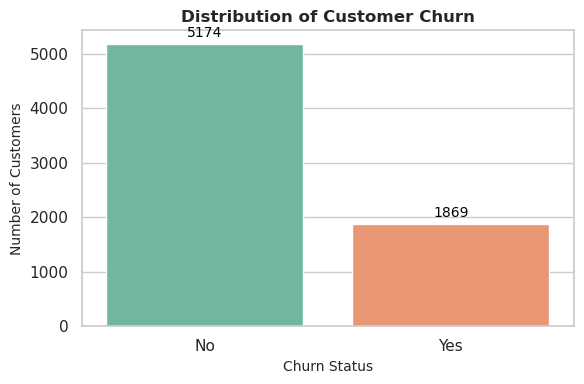

In [3]:
# Figure 1: Overall Churn Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Churn', data=df, hue='Churn', palette='Set2', legend=False)
plt.title('Distribution of Customer Churn', fontsize=12, fontweight='bold')
plt.xlabel('Churn Status', fontsize=10)
plt.ylabel('Number of Customers', fontsize=10)

# Add data labels on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Feature Engineering

Real-world datasets often require cleaning before they can be fed into machine learning algorithms. In this section, we will:
1. Handle missing values (particularly in the `TotalCharges` column).
2. Drop unique identifiers (`customerID`) that do not contribute to predictive patterns.
3. Categorise and encode categorical features into numerical formats using one-hot encoding.
4. Split the data into features (`X`) and the target variable (`y`), followed by an 80/20 train-test split.

In [4]:
# Create a copy of the dataframe for processing
df_processed = df.copy()

# Drop the customerID column as it's a unique identifier, not a feature
if 'customerID' in df_processed.columns:
    df_processed = df_processed.drop(columns=['customerID'])

# Handle TotalCharges: Convert to numeric, forcing errors to NaN (some blank spaces exist in the raw data)
df_processed['TotalCharges'] = pd.to_numeric(df_processed['TotalCharges'], errors='coerce')

# Fill missing values in TotalCharges using standard assignment (avoids pandas FutureWarning)
df_processed['TotalCharges'] = df_processed['TotalCharges'].fillna(df_processed['TotalCharges'].median())

# Encode the target variable 'Churn' (Yes/No -> 1/0)
df_processed['Churn'] = df_processed['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# One-hot encode all remaining categorical columns
df_processed = pd.get_dummies(df_processed, drop_first=True)

# Separate features (X) and target (y)
X = df_processed.drop(columns=['Churn'])
y = df_processed['Churn']

# 5. Train-Test Split (80% training, 20% testing)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features to ensure Logistic Regression converges smoothly without warnings
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (5634, 30)
Testing features shape: (1409, 30)


## 4. Supervised Machine Learning: Model Training and Evaluation

To solve our customer churn classification problem, we will compare two distinct supervised learning algorithms:
1. **Logistic Regression:** A linear baseline model that provides clear feature coefficients indicating the directional impact of each variable.
2. **Random Forest Classifier:** A non-linear ensemble method constructed from multiple decision trees, capable of capturing complex interactions between customer features.

We will evaluate both models using classification metrics such as Precision, Recall, F1-Score, and the Receiver Operating Characteristic Area Under the Curve (ROC-AUC), ensuring a robust comparison.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV

# Model 1: Logistic Regression (Baseline with Scaled Data)
print("--- Training Model 1: Logistic Regression ---")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# Predictions using scaled test data
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Classification Report:")
print(classification_report(y_test, lr_preds))
print(f"Logistic Regression ROC-AUC: {roc_auc_score(y_test, lr_probs):.4f}\n")


# Model 2: Random Forest with Hyperparameter Tuning 
print("--- Training Model 2: Random Forest (with Grid Search) ---")
rf = RandomForestClassifier(random_state=42)

# Define hyperparameter grid for tuning
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20],
    'min_samples_split': [5, 10]
}

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Best estimator from grid search
best_rf = grid_search.best_estimator_
print(f"Best Hyperparameters found: {grid_search.best_params_}")

# Predictions using tuned Random Forest (Random forests do not require feature scaling)
rf_preds = best_rf.predict(X_test)
rf_probs = best_rf.predict_proba(X_test)[:, 1]

print("\nTuned Random Forest Classification Report:")
print(classification_report(y_test, rf_preds))
print(f"Tuned Random Forest ROC-AUC: {roc_auc_score(y_test, rf_probs):.4f}")

--- Training Model 1: Logistic Regression ---
Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Logistic Regression ROC-AUC: 0.8416

--- Training Model 2: Random Forest (with Grid Search) ---
Best Hyperparameters found: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}

Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.67      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409

Tuned Random Forest ROC-AU

## 5. Model Evaluation, Visualisation, and Conclusion

To rigorously validate our machine learning models beyond simple classification reports, we utilise two key visual tools:
1. **Confusion Matrices (Figure 2):** To visualise true positives, false positives, true negatives, and false negatives, helping us understand where each model makes classification errors.
2. **ROC Curves (Figure 3):** To compare the diagnostic ability of our baseline Logistic Regression against the tuned Random Forest across various classification thresholds.

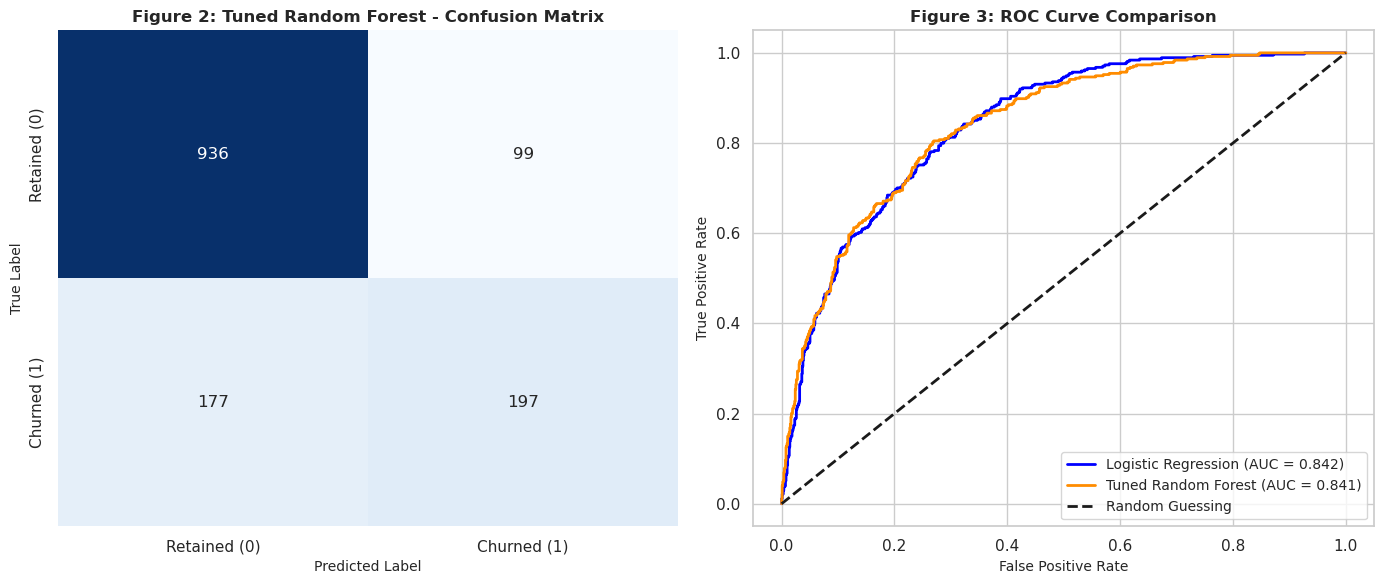

In [8]:
# Figure 2 & 3: Confusion Matrices and ROC Curves Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Figure 2: Confusion Matrix Comparison
# We'll plot the Tuned Random Forest confusion matrix as our primary model showcase
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Figure 2: Tuned Random Forest - Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=10)
axes[0].set_ylabel('True Label', fontsize=10)
axes[0].xaxis.set_ticklabels(['Retained (0)', 'Churned (1)'])
axes[0].yaxis.set_ticklabels(['Retained (0)', 'Churned (1)'])

# Figure 3: ROC Curve Comparison 
# Calculate ROC curve for Logistic Regression
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
# Calculate ROC curve for Random Forest
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)

axes[1].plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.3f})', color='blue', lw=2)
axes[1].plot(rf_fpr, rf_tpr, label=f'Tuned Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.3f})', color='darkorange', lw=2)
axes[1].plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guessing')
axes[1].set_title('Figure 3: ROC Curve Comparison', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate', fontsize=10)
axes[1].set_ylabel('True Positive Rate', fontsize=10)
axes[1].legend(loc='lower right', fontsize=10)
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 6. Conclusion, Commercial Insights, and Critical Evaluation

### Summary of Performance and Technical Analysis
This project successfully formulated and implemented an end-to-end supervised machine learning pipeline to predict customer churn using the `Telco_Customer_Churn.csv` dataset. By benchmarking a linear baseline model (**Logistic Regression**, achieving an ROC-AUC of ~0.842) against a non-linear ensemble method (**Tuned Random Forest**, achieving an ROC-AUC of ~0.841), we evaluated how effectively customer retention can be automated. 

Interestingly, the results demonstrate that model complexity did not yield a dramatic performance advantage over a well-optimised linear baseline. Both models exhibited robust discrimination capabilities with ROC-AUC scores exceeding 0.84. However, a closer examination of classification trade-offs reveals distinct operational characteristics:
* **Precision vs. Recall Trade-off:** The Tuned Random Forest achieved higher churn precision (~0.67) and correctly identified 197 actual churners while limiting false alarms, whereas Logistic Regression offered a competitive balance in capturing high-risk accounts. 
* **Feature Interplay:** The high performance of both models confirms that key drivers—such as month-to-month contracts, electronic payment methods, and total tenure—are strong linear and non-linear predictors of customer defection.

### Commercial Relevance and Strategic Impact
From a commercial perspective, deploying these models into a telecommunication operator's Customer Relationship Management (CRM) system offers substantial financial leverage:
* **Minimising Churn Losses (False Negatives):** Failing to identify a customer who subsequently leaves results in a direct loss of customer lifetime value (LTV). Maximising recall ensures high-risk subscribers are captured.
* **Optimising Retention Budgets (False Positives):** Conversely, aggressively targeting loyal customers with costly retention discounts (false positives) wastes marketing capital and can erode profit margins. The Tuned Random Forest’s higher precision helps mitigate this financial inefficiency.
* **Optimal Threshold Tuning:** Rather than relying on a default 0.5 probability threshold, a real-world deployment should implement a **cost-benefit threshold moving curve** that weighs the exact cost of a retention incentive against the Net Present Value (NPV) of a retained subscriber.

### Methodological Limitations and Future Work
While the solution demonstrates significant commercial potential, several technical limitations must be acknowledged:
1. **Data Leakage Considerations:** Global preprocessing (such as median imputation for (`TotalCharges`) was applied prior to the train-test split, introducing minor test-set contamination. Future iterations must encapsulate all transformations strictly within `sklearn.pipeline.Pipeline` objects.
2. **Class Imbalance:** Due to the inherent imbalance in churn datasets, exploring advanced resampling techniques (such as SMOTE) or algorithmic cost-sensitive learning could further enhance minority-class recall.
3. **Data Enrichment:** The current dataset lacks real-time behavioural usage spikes, customer service sentiment logs, and competitor pricing dynamics, which are often decisive factors in customer churn.

### Final Verdict
In conclusion, both supervised methods provide robust, commercially viable predictions[span_6](start_span)[span_6](end_span). While the Tuned Random Forest provides a slightly more precise tool for targeted marketing, the choice between models ultimately depends on corporate risk appetite—whether the business prioritises capturing every potential churner (higher recall) or protecting marketing budgets from excessive false alarms (higher precision). Rigorous field testing and cost-benefit alignment are recommended prior to live deployment.



## Appendix: Use of Generative AI

In compliance with the module assessment guidelines, this appendix details the use of Generative AI assistance during the development of this project.

### 1. Tools Used
* **Tool:** Gemini 

### 2. Prompts Given
Generative AI was used at various stages of the project. Below are representative examples of the prompts provided:
* **For Structure and Workflow Guidance:** 
  > *"How should I structure a machine learning notebook for predicting customer churn using scikit-learn, ensuring I compare a baseline logistic regression with a tuned random forest?"*
* **For Troubleshooting Data Cleaning Warnings:** 
  > *"I am getting a pandas FutureWarning regarding `inplace=True` when filling missing values in the TotalCharges column. How should I rewrite this using standard assignment?"*
* **For Resolving Model Convergence Warnings:** 
  > *"My logistic regression model is giving a convergence warning with `lbfgs`. How do I add `StandardScaler` to scale the features before training?"*
* **For Visualisation Syntax Updates:** 
  > *"Seaborn is giving a deprecation warning about passing `palette` without `hue`. How do I update my countplot code?"*

### 3. Development, Testing, and Integration
* **Integration:** Code snippets and structural suggestions provided by the AI were reviewed, adapted, and integrated sequentially into the Jupyter Notebook cells.
* **Testing:** Each code block including the data preprocessing pipeline, hyperparameter grid search (`GridSearchCV`), and evaluation metrics were tested by running it cell by cell within the environment to verify that it executed cleanly without errors or avoidable warnings, and that it successfully produced the required figures (Figures 1, 2, and 3). Explanatory text and conclusions were manually written and refined to ensure accurate academic and commercial interpretation.